In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from Bio import SeqIO
from Bio.SeqUtils import seq3

In [4]:
aa_instect_df = pd.read_csv("../data/midori_Blattodea_aa_fracs.tsv", sep='\t')

In [12]:
cytb_insect_df = aa_instect_df[aa_instect_df['Gene_name'] == 'Cytb'].reset_index(drop=True)

In [13]:
cytb_insect_df

,Species_name,Organism,Gene_name,Phe_frac,Leu_frac,Leu2_frac,Ser_frac,Pro_frac,Cys_frac,Trp_frac,...,Ser2_frac,Asp_frac,Glu_frac,Asn_frac,Lys_frac,Val_frac,Ile_frac,Met_frac,Ala_frac,Thr_frac
0,Acanthotermes_acanthothorax_187525,Termites,Cytb,0.044974,0.021164,0.005291,0.097884,0.018519,0.103175,0.066138,...,0.010582,0.068783,0.068783,0.026455,0.015873,0.126984,0.018519,0.013228,0.013228,0.005291
1,Acholotermes_chirotus_1934430,Termites,Cytb,0.039683,0.021164,0.007937,0.116402,0.010582,0.119048,0.066138,...,0.010582,0.055556,0.055556,0.026455,0.023810,0.103175,0.042328,0.018519,0.007937,0.007937
2,Aciculitermes_aciculatus_1934431,Termites,Cytb,0.042328,0.023810,0.005291,0.111111,0.007937,0.097884,0.052910,...,0.044974,0.044974,0.042328,0.039683,0.037037,0.095238,0.031746,0.029101,0.015873,0.010582
3,Aciculitermes_maymyoensis_229658,Termites,Cytb,0.042328,0.018519,0.007937,0.100529,0.021164,0.100529,0.050265,...,0.039683,0.050265,0.058201,0.047619,0.031746,0.074074,0.047619,0.037037,0.010582,0.007937
4,Acidnotermes_praus_1934432,Termites,Cytb,0.024064,0.026738,0.016043,0.085561,0.032086,0.104278,0.069519,...,0.021390,0.037433,0.045455,0.034759,0.040107,0.096257,0.034759,0.029412,0.013369,0.013369
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
392,Tumulitermes_pastinator_286182,Termites,Cytb,0.039683,0.021164,0.007937,0.100529,0.015873,0.116402,0.060847,...,0.021164,0.066138,0.068783,0.026455,0.021164,0.121693,0.026455,0.013228,0.021164,0.002646
393,Tumulitermes_recalvus_1934613,Termites,Cytb,0.039683,0.023810,0.005291,0.108466,0.007937,0.119048,0.055556,...,0.026455,0.037037,0.066138,0.037037,0.029101,0.108466,0.029101,0.021164,0.007937,0.015873
394,Verrucositermes_tuberosus_378004,Termites,Cytb,0.044974,0.023810,0.002646,0.100529,0.013228,0.113757,0.060847,...,0.029101,0.060847,0.060847,0.034392,0.018519,0.108466,0.031746,0.015873,0.021164,0.007937
395,Zootermopsis_angusticollis_7503,Termites,Cytb,0.050265,0.023810,0.002646,0.116402,0.007937,0.084656,0.082011,...,0.023810,0.068783,0.058201,0.034392,0.021164,0.103175,0.039683,0.018519,0.007937,0.007937


In [16]:
# Select amino acid frequencies
aa_cols = [
    col for col in cytb_insect_df.columns
    if col.endswith("_frac")
]

# Prepare PCA matrix
X = cytb_insect_df[aa_cols].copy()

# Standardize variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA
pca = PCA(n_components=2)
scores = pca.fit_transform(X_scaled)

# PCA scores
pca_df = cytb_insect_df[
    ["Species_name", "Organism"]
].copy()

pca_df["PC1"] = scores[:, 0]
pca_df["PC2"] = scores[:, 1]

# PCA loadings
loadings = pd.DataFrame(
    pca.components_.T,
    index=aa_cols,
    columns=["PC1", "PC2"]
)

# Explained variance
explained_variance = pca.explained_variance_ratio_ * 100

print("Explained variance:")
print(f"PC1: {explained_variance[0]:.2f}%")
print(f"PC2: {explained_variance[1]:.2f}%")

Explained variance:
PC1: 41.82%
PC2: 16.43%


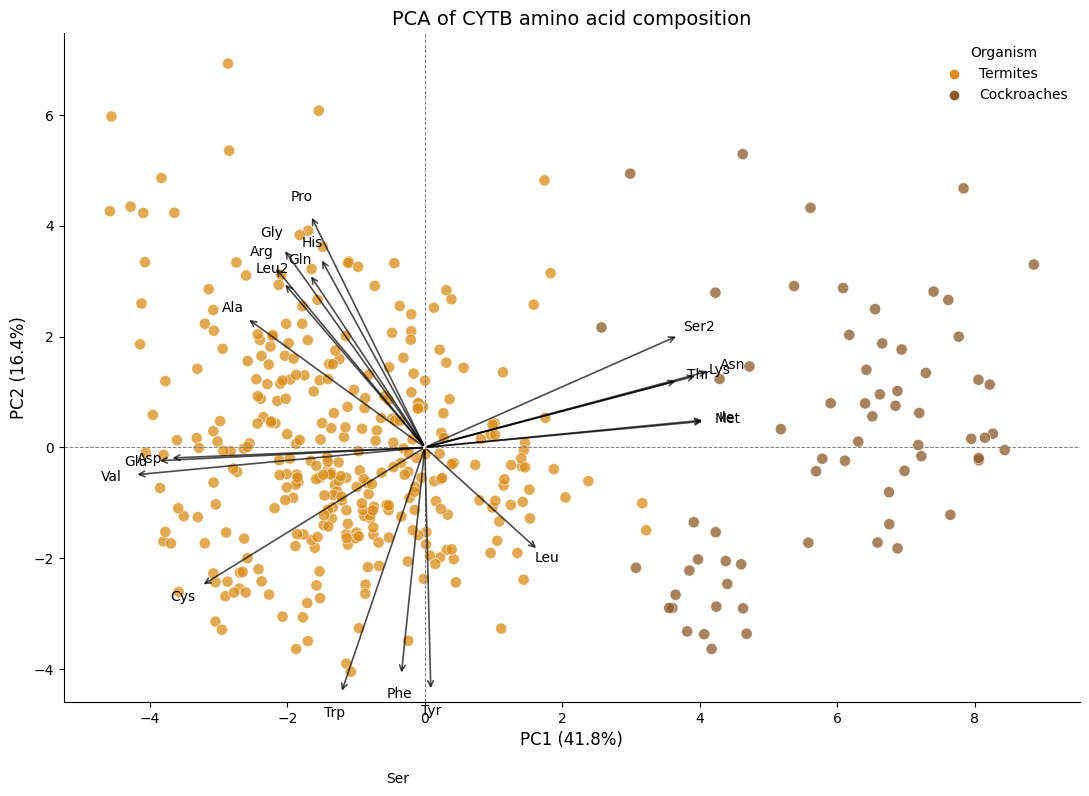

In [17]:
fig, ax = plt.subplots(figsize=(11, 8))

palette = {
    "Termites": "#D98C1A",
    "Cockroaches": "#8B5A2B"
}

# Species
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Organism",
    palette=palette,
    s=65,
    alpha=0.75,
    edgecolor="white",
    linewidth=0.5,
    ax=ax
)

# Scale arrows to PCA scores
scale = 0.8 * min(
    np.max(np.abs(scores[:, 0])) / np.max(np.abs(loadings["PC1"])),
    np.max(np.abs(scores[:, 1])) / np.max(np.abs(loadings["PC2"]))
)

# Amino acid vectors
for aa in aa_cols:

    x = loadings.loc[aa, "PC1"] * scale
    y = loadings.loc[aa, "PC2"] * scale

    ax.annotate(
        "",
        xy=(x, y),
        xytext=(0, 0),
        arrowprops=dict(
            arrowstyle="->",
            color="black",
            lw=1.2,
            alpha=0.7
        )
    )

    ax.text(
        x * 1.08,
        y * 1.08,
        aa.replace("_frac", ""),
        fontsize=10,
        ha="center",
        va="center"
    )

ax.axhline(0, color="gray", linestyle="--", linewidth=0.7)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.7)

ax.set_xlabel(f"PC1 ({explained_variance[0]:.1f}%)", fontsize=12)
ax.set_ylabel(f"PC2 ({explained_variance[1]:.1f}%)", fontsize=12)

ax.set_title(
    "PCA of CYTB amino acid composition",
    fontsize=14
)

ax.legend(title="Organism", frameon=False)

sns.despine()
plt.tight_layout()
plt.show()

In [20]:
# 20 standard amino acids
amino_acids = list("ACDEFGHIKLMNPQRSTVWY")

records = []

for record in SeqIO.parse("../data/all_insects_CO1seqs.faa", "fasta"):

    sequence = str(record.seq).upper()

    # Keep standard amino acids only
    sequence = "".join(
        aa for aa in sequence
        if aa in amino_acids
    )

    if len(sequence) == 0:
        continue

    # Calculate amino acid frequencies
    aa_freq = {
        f"{aa}_frac": sequence.count(aa) / len(sequence)
        for aa in amino_acids
    }

    records.append({
        "Species_name": record.description,
        "Length": len(sequence),
        **aa_freq
    })

cox1_df = pd.DataFrame(records)

cox1_df.head()

,Species_name,Length,A_frac,C_frac,D_frac,E_frac,F_frac,G_frac,H_frac,I_frac,...,M_frac,N_frac,P_frac,Q_frac,R_frac,S_frac,T_frac,V_frac,W_frac,Y_frac
0,MF040934.1 [Heterolepisma_sclerophylla_2171747],215,0.074419,0.0,0.027907,0.018605,0.055814,0.102326,0.013953,0.088372,...,0.065116,0.051163,0.060465,0.009302,0.023256,0.079070,0.069767,0.065116,0.023256,0.018605
1,MT108230.1 [Lepisma_saccharina_50586],512,0.072266,0.0,0.029297,0.019531,0.072266,0.085938,0.031250,0.089844,...,0.058594,0.033203,0.056641,0.019531,0.021484,0.080078,0.072266,0.070312,0.029297,0.031250
2,MW129798.1 [Trichatelura_manni_2873228],224,0.098214,0.0,0.040179,0.004464,0.075893,0.102679,0.017857,0.098214,...,0.058036,0.040179,0.062500,0.013393,0.022321,0.071429,0.044643,0.058036,0.026786,0.017857
3,JX412826.1 [Brachinus_crepitans_877828],514,0.066148,0.0,0.027237,0.019455,0.081712,0.091440,0.029183,0.097276,...,0.054475,0.035019,0.050584,0.023346,0.019455,0.089494,0.064202,0.060311,0.027237,0.035019
4,HM433229.1 [Brachinus_elongatulus_1977114],219,0.082192,0.0,0.031963,0.013699,0.063927,0.105023,0.018265,0.077626,...,0.063927,0.041096,0.063927,0.009132,0.022831,0.082192,0.063927,0.068493,0.022831,0.018265


In [22]:
cox1_df["Accession"] = cox1_df["Species_name"].str.extract(
    r"^(\S+)"
)

cox1_df["Species_name"] = cox1_df["Species_name"].str.extract(
    r"\[([^\]]+)\]"
)[0]

cox1_df.head()

,Species_name,Length,A_frac,C_frac,D_frac,E_frac,F_frac,G_frac,H_frac,I_frac,...,N_frac,P_frac,Q_frac,R_frac,S_frac,T_frac,V_frac,W_frac,Y_frac,Accession
0,Heterolepisma_sclerophylla_2171747,215,0.074419,0.0,0.027907,0.018605,0.055814,0.102326,0.013953,0.088372,...,0.051163,0.060465,0.009302,0.023256,0.079070,0.069767,0.065116,0.023256,0.018605,MF040934.1
1,Lepisma_saccharina_50586,512,0.072266,0.0,0.029297,0.019531,0.072266,0.085938,0.031250,0.089844,...,0.033203,0.056641,0.019531,0.021484,0.080078,0.072266,0.070312,0.029297,0.031250,MT108230.1
2,Trichatelura_manni_2873228,224,0.098214,0.0,0.040179,0.004464,0.075893,0.102679,0.017857,0.098214,...,0.040179,0.062500,0.013393,0.022321,0.071429,0.044643,0.058036,0.026786,0.017857,MW129798.1
3,Brachinus_crepitans_877828,514,0.066148,0.0,0.027237,0.019455,0.081712,0.091440,0.029183,0.097276,...,0.035019,0.050584,0.023346,0.019455,0.089494,0.064202,0.060311,0.027237,0.035019,JX412826.1
4,Brachinus_elongatulus_1977114,219,0.082192,0.0,0.031963,0.013699,0.063927,0.105023,0.018265,0.077626,...,0.041096,0.063927,0.009132,0.022831,0.082192,0.063927,0.068493,0.022831,0.018265,HM433229.1


In [23]:
# Select amino acid frequencies
aa_cols = [f"{aa}_frac" for aa in amino_acids]

X = cox1_df[aa_cols].copy()

# Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA
pca = PCA(n_components=2)
scores = pca.fit_transform(X_scaled)

# Scores
pca_df = cox1_df[["Species_name", "Accession"]].copy()

pca_df["PC1"] = scores[:, 0]
pca_df["PC2"] = scores[:, 1]

# Loadings
loadings = pd.DataFrame(
    pca.components_.T,
    index=amino_acids,
    columns=["PC1", "PC2"]
)

explained_variance = pca.explained_variance_ratio_ * 100

print(f"PC1: {explained_variance[0]:.2f}%")
print(f"PC2: {explained_variance[1]:.2f}%")

PC1: 39.73%
PC2: 20.55%


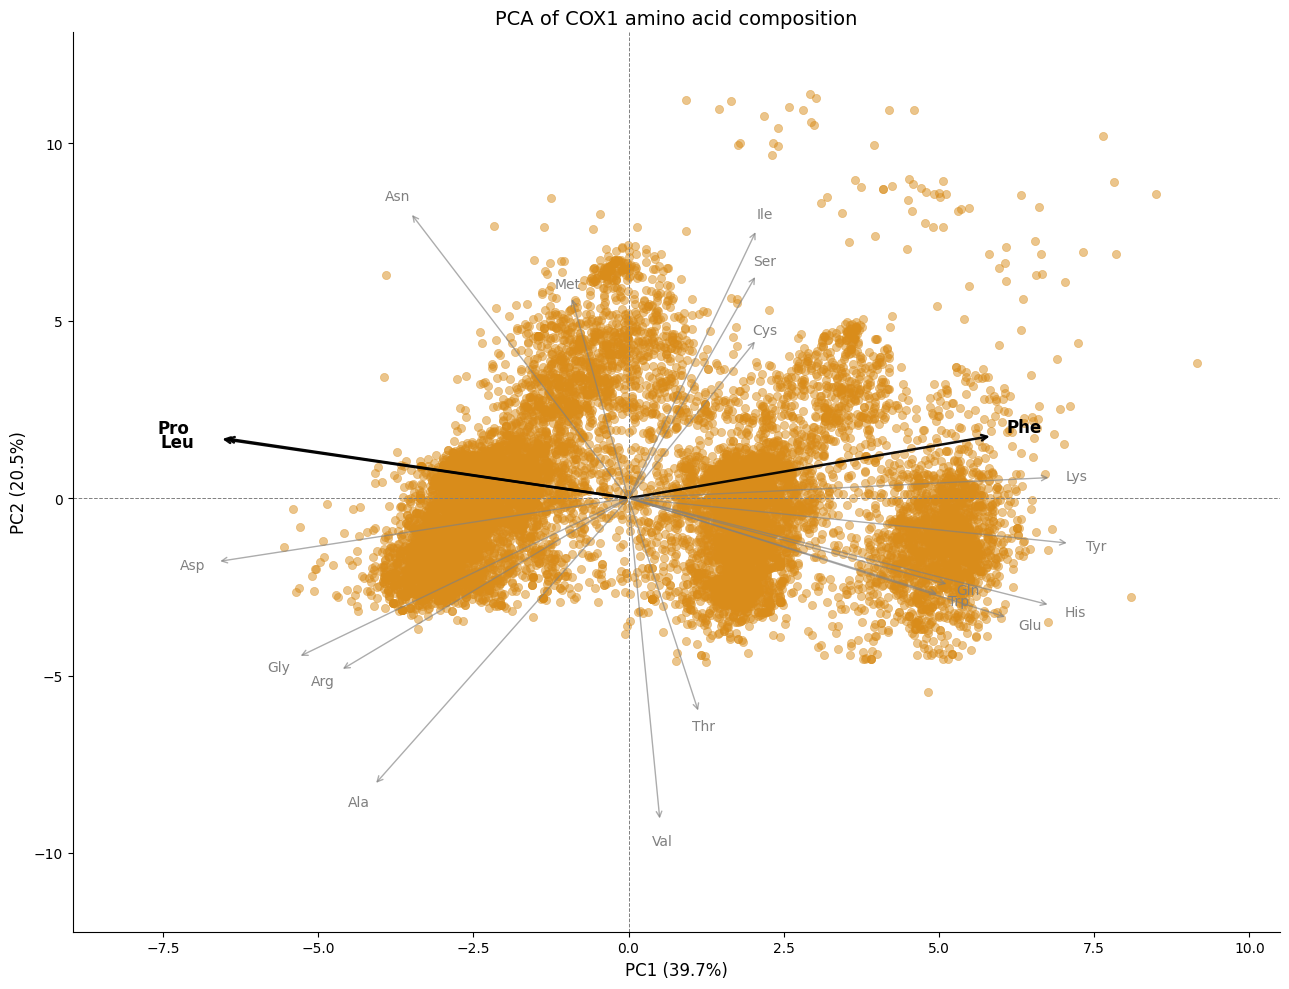

In [27]:
fig, ax = plt.subplots(figsize=(13, 10))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    color="#D98C1A",
    s=35,
    alpha=0.5,
    edgecolor=None,
    ax=ax
)

scale = 0.8 * min(
    np.max(np.abs(scores[:, 0])) / np.max(np.abs(loadings["PC1"])),
    np.max(np.abs(scores[:, 1])) / np.max(np.abs(loadings["PC2"]))
)

highlight_aas = {"P", "F", "L"}

# ручные сдвиги подписей
label_offsets = {
    "P": (-0.35,  0.20),   # Pro чуть левее и выше
    "L": (-0.35, -0.20),   # Leu чуть левее и ниже
    "F": ( 0.15,  0.15),   # Phe чуть правее и выше
}

arrow_endpoints = []

for aa in amino_acids:
    x = loadings.loc[aa, "PC1"] * scale
    y = loadings.loc[aa, "PC2"] * scale
    arrow_endpoints.append((x, y))

    is_highlight = aa in highlight_aas

    line_color = "black" if is_highlight else "gray"
    lw = 1.8 if is_highlight else 1.0
    alpha = 0.95 if is_highlight else 0.65
    fontsize = 12 if is_highlight else 10
    fontweight = "bold" if is_highlight else "normal"

    # стрелка
    ax.annotate(
        "",
        xy=(x, y),
        xytext=(0, 0),
        arrowprops=dict(
            arrowstyle="->",
            color=line_color,
            lw=lw,
            alpha=alpha
        )
    )

    # базовая позиция подписи
    label_x = x * 1.06
    label_y = y * 1.06

    # если есть ручной сдвиг — применяем
    dx, dy = label_offsets.get(aa, (0, 0))
    label_x += dx
    label_y += dy

    ax.text(
        label_x,
        label_y,
        seq3(aa),
        fontsize=fontsize,
        fontweight=fontweight,
        color=line_color,
        ha="center",
        va="center"
    )

ax.axhline(0, color="gray", linestyle="--", linewidth=0.7)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.7)

# расширим пределы осей
all_x = list(pca_df["PC1"]) + [x * 1.15 for x, y in arrow_endpoints]
all_y = list(pca_df["PC2"]) + [y * 1.15 for x, y in arrow_endpoints]

x_pad = 0.08 * (max(all_x) - min(all_x))
y_pad = 0.08 * (max(all_y) - min(all_y))

ax.set_xlim(min(all_x) - x_pad, max(all_x) + x_pad)
ax.set_ylim(min(all_y) - y_pad, max(all_y) + y_pad)

ax.set_xlabel(f"PC1 ({explained_variance[0]:.1f}%)", fontsize=12)
ax.set_ylabel(f"PC2 ({explained_variance[1]:.1f}%)", fontsize=12)
ax.set_title("PCA of COX1 amino acid composition", fontsize=14)

sns.despine()
plt.tight_layout()
plt.show()